# 04 — Linear models: one model for the whole flight, then one per flight segment

**Input:** `data/processed/features/features.parquet`, built in notebook 03: ~2M state vectors of ~34,000 flights, already split into train / validation / test **by flight**.

**Goal:** predictive models of the remaining flight time, kept deliberately simple: **linear regressions**, in two parts.
- **Part 1 — one model for the whole flight.** Three linear candidates (Ridge, and linear models trained with a Huber or an MAE loss) are tuned, compared with the chosen metrics, and the best one is analysed: what it learns, whether it overfits, where it fails.
- **Part 2 — one model per flight segment** (before the cruise, cruise, after the cruise). Does a separate set of weights per segment help, and what does it change for the preprocessing? Three preprocessing strategies are compared, the best one is selected, then compared with the model selected in part 1.

**Why linear models?** They train in seconds, their coefficients can be read, and they set the bar that every more complex model will have to beat.

> **Assumption of part 2: the phase of flight is known at any time.** Each state vector is sent to the model of its segment, given by `phase_of_flight` (notebook 02). We assume that the phase of flight is accessible at any moment of a flight. For live flights, a possible source is the flight plan filed by the crew, which gives the planned cruise level: before reaching it, the aircraft is climbing; when it leaves it for its destination, it is descending. This is not done here: our `phase_of_flight` is computed from the recorded trajectory.

**Evaluation protocol.**

| Set | Used for |
|---|---|
| train (70 % of the flights) | fitting everything that is learnt: weights, scaler, encoder |
| validation (15 %) | choosing hyperparameters and comparing models |
| test (15 %) | **not used here**: kept untouched for the final evaluation of the project |

All errors are in **minutes** (the label is in seconds). The metrics are chosen once, below, and used everywhere.

## Choice of the error metrics

| Metric | Why this metric | Role |
|---|---|---|
| **MAE** (mean absolute error) | It is the error felt by the users: on average, how many minutes separate the announced arrival time from the real one. | **decision metric**: selects the hyperparameters, the loss, the strategies |
| **MAE per flight segment** (`pre`, `cruise`, `post`) | The model must be reliable during the whole flight, not only on average: the cruise holds half of the rows, so a better overall MAE could hide a model that got worse in the climb or in the approach. | **guardrail**: a better overall MAE must not hide a degraded segment |
| **95th percentile** of the absolute error | The large errors are the ones that disrupt the users (a pick-up missed, a connection or a transfer badly planned): 95 % of the predictions must stay within a bounded error. | **guardrail**: the large errors must not explode |
| **Median** absolute error | It describes the typical error, the centre of the distribution of the errors: compared with the MAE, it shows how much the average is pulled up by a minority of large errors. | reported alongside, not used to decide |

**Decision rule.** The model with the lowest MAE is preferred, unless it noticeably degrades a segment MAE or the 95th percentile. A difference counts only if it is larger than the statistical noise (confidence intervals below).

**Why an MAE weighted by rows** (every sampled state vector counts once):
- *It is the user's experience:* each row is a moment at which a prediction is requested, so the MAE reads directly as "at a random moment of a flight, the prediction is off by X minutes on average".
- *Its weights are realistic:* the 15 / 30 / 15 sampling gives the segments 25 / 50 / 25 % of the rows, close to the share of time the flights actually spend in them (about 20 / 53 / 27 % of the state vectors before sampling, notebook 02). The row-weighted MAE is therefore close to the error at a moment drawn at random during a flight.
- *It is consistent with the training:* the MAE loss minimizes exactly this mean over the rows, so the models are selected with the criterion they optimize.

**Information only** (shown, never used to decide): the MAE by remaining time and the **relative error** (MAE / mean true remaining time of the group). They explain *where* the errors come from, but a 10-minute error does not mean the same thing 15 minutes or 8 hours before the landing, so they would be misleading as selection criteria.

**Uncertainty: confidence intervals by bootstrap over the flights.** The validation set is one sample of ~5,000 flights; another sample would give slightly different numbers. To measure this:
1. we compute, for each validation flight, the sum of its absolute errors and its number of rows;
2. we draw as many flights as there are in the validation set, **with replacement**;
3. we compute the MAE on this sample, and repeat 1,000 times;
4. the 95 % confidence interval goes from the 2.5th to the 97.5th percentile of these 1,000 MAEs.

Flights are resampled, not rows, because the 60 rows of a flight are correlated: treating them as independent would give intervals that are far too narrow. To **compare two models**, both are evaluated on the **same** resampled flights and the interval is computed on their *difference* (paired bootstrap).

## 0. Setup

The paths, the feature lists, the preprocessing and the evaluation functions (`evaluate`, `bootstrap_comparison`, `remaining_time_report`) are in the package `src/opensky_eta`, shared with the next notebooks: every model of the project is evaluated with exactly the same code. The constructors of the linear models (`make_sgd_pipeline`, `make_mae_regressor`…) are in `models.py`, also used by `python -m opensky_eta.train` to retrain the selected models.

In [1]:
import warnings

import joblib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import Pipeline

from opensky_eta.config import (
    CATEGORICAL_FEATURES, FEATURES_PATH, FLIGHT_KEY, LABEL, LINEAR_MODEL_PATH, LINEAR_PREDICTIONS_PATH,
    MIN_AIRPORT_FLIGHTS, N_POINTS, NUMERIC_FEATURES, PHASE_TO_SEGMENT, POINTS_PER_FLIGHT,
    PROJECT_DIR, RANDOM_STATE, SECONDS_PER_HOUR, SEGMENT_MODELS_PATH, SEGMENTS,
)
from opensky_eta.evaluation import (
    REMAINING_BINS_MIN, REMAINING_LABELS, bootstrap_comparison, error_concentration, evaluate,
    flag_suspicious_labels, flight_errors, remaining_time_report, suspicious_label_report,
)
from opensky_eta.models import MAE_LOSS, make_mae_regressor, make_sgd_pipeline, make_sgd_regressor
from opensky_eta.plotting import set_plot_style
from opensky_eta.preprocessing import make_preprocessor

set_plot_style()



# Part 1 — One linear model for the whole flight

## 1. Data

`X` holds the raw (unscaled) features and `y` the label, in seconds.

In [2]:
features = pd.read_parquet(FEATURES_PATH)
train = features[features["split"] == "train"]
validation = features[features["split"] == "validation"]

X_train, y_train = train[NUMERIC_FEATURES + CATEGORICAL_FEATURES], train[LABEL]
X_val, y_val = validation[NUMERIC_FEATURES + CATEGORICAL_FEATURES], validation[LABEL]

# Evaluation helpers: flight segment of each row (for the MAE per segment) and flight id of
# each validation row (for the bootstrap). phase_of_flight is used to evaluate, never as a feature.
train_segment = train["phase_of_flight"].map(PHASE_TO_SEGMENT)
val_segment = validation["phase_of_flight"].map(PHASE_TO_SEGMENT)
val_flight = validation.groupby(FLIGHT_KEY, sort=False).ngroup().to_numpy()

print(f"Train: {len(X_train):,} rows, validation: {len(X_val):,} rows "
      f"({val_flight.max() + 1:,} flights), {X_train.shape[1]} raw features")
display((y_train / 60).describe(percentiles=[0.1, 0.5, 0.9]).round(1)
        .rename("remaining time, train (min)").to_frame().T)

Train: 1,439,400 rows, validation: 308,460 rows (5,141 flights), 24 raw features


,count,mean,std,min,10%,50%,90%,max
"remaining time, train (min)",1439400.0,66.9,85.2,0.0,10.0,42.4,135.4,1195.0


## 2. Baselines

Before any learning, two references that every model must beat:
- **a constant**: always predict the median remaining time of the training set (the best constant for the MAE);
- **the naive time to arrival** from notebook 03: remaining distance / current ground speed.

In [3]:
results = {}
results["Constant (train median)"] = evaluate(y_val, np.full(len(y_val), y_train.median()), val_segment)
results["Naive: distance / speed"] = evaluate(y_val, validation["naive_time_to_arrival_s"], val_segment)
display(pd.DataFrame(results).T.round(2))

,MAE (min),median AE (min),P95 AE (min),MAE pre (min),MAE cruise (min),MAE post (min)
Constant (train median),44.01,23.52,149.03,78.59,34.22,29.01
Naive: distance / speed,16.06,8.71,42.53,30.68,13.59,6.37


## 3. The candidate models

Three linear models are compared. They share the same features, the same preprocessing and the same form; they only differ by the **loss** they minimize:

| Candidate | Loss | Penalty | Solved by | Hyperparameters to tune |
|---|---|---|---|---|
| **Ridge** | squared error (MSE) | L2, strength α | conjugate gradient | α |
| **Linear, Huber loss** | Huber, threshold δ | L2, strength α | stochastic gradient descent | α, δ |
| **Linear, MAE loss** | absolute error (MAE) | L2, strength α | stochastic gradient descent | α |

Each candidate is tuned on the validation set (section 4), the tuned candidates are compared with the chosen metrics and the best one on the MAE is selected (section 5), and only the selected model is analysed in detail (section 6).

### 3.1 The linear model and the L2 penalty (Ridge)

$$\hat{y} = b + w_1 x_1 + w_2 x_2 + \dots + w_p x_p$$

**Ridge** chooses the weights $w$ and the intercept $b$ that minimize the squared errors, plus a penalty on the size of the weights:

$$\min_{w, b} \; \sum_{i=1}^{n} \left(y_i - \hat{y}_i\right)^2 \; + \; \alpha \sum_{j=1}^{p} w_j^2$$

- Because the penalty compares the weights with each other, the features must be on the same scale: hence the `StandardScaler`.
- For this loss, the minimum is the exact solution of a linear system, $(X^\top X + \alpha I)\,w = X^\top y$. scikit-learn solves this system with the **conjugate gradient** method (because the preprocessed matrix is sparse, mostly zeros from the one-hot of the airports): an iterative solver, which stops when the residual of the system is below a tolerance (`tol=1e-4`).

**The scikit-learn pipeline.**
- `pipeline.fit(X_train, y_train)` fits the scaler and the encoder **on the training set**, transforms it, then fits the weights;
- `pipeline.predict(X_val)` applies the **same** fitted transformations to the validation set, then the weights.

A first Ridge, with an arbitrary α:

In [4]:
ridge = Pipeline([
    ("preprocess", make_preprocessor()),
    ("model", Ridge(alpha=1.0)),
])
ridge.fit(X_train, y_train)    # learns the scaling, the encoding and the weights on train
y_pred = ridge.predict(X_val)  # applies them to the validation flights

display(pd.Series(evaluate(y_val, y_pred, val_segment)).round(3).to_frame("Ridge, alpha = 1"))

,"Ridge, alpha = 1"
MAE (min),11.981
median AE (min),6.141
P95 AE (min),37.154
MAE pre (min),18.265
MAE cruise (min),9.488
MAE post (min),10.683


### 3.2 Minimizing the MAE and the Huber loss: `SGDRegressor`

Only the squared loss leads to a linear system with an exact solution. For the MAE and the Huber loss, the minimum has to be found by an iterative descent. scikit-learn's `SGDRegressor` fits **exactly the same kind of model as Ridge** (linear, with an L2 penalty of strength α) and lets us choose the loss:

| Loss | `SGDRegressor` parameters |
|---|---|
| Huber | `loss="huber", epsilon=δ` |
| MAE | `loss="epsilon_insensitive", epsilon=0` (the ε-insensitive loss $\max(0, \lvert r \rvert - \varepsilon)$ with ε = 0 is $\lvert r \rvert$) |

It minimizes $\frac{1}{n}\sum_i L(y_i, \hat{y}_i) + \alpha \cdot \frac{1}{2}\sum_j w_j^2$, where $L$ is the chosen loss.

Training stops when five consecutive epochs no longer improve the loss (`tol`) or after `max_iter` epochs.

Practical points:
- the features must be scaled (the pipeline does it);
- the target should be of order 1: we train on the remaining time **in hours**, and convert the predictions back to seconds; δ is then expressed in hours;
- `average=True` averages the weights over the updates, which makes the result more stable;
- $\alpha$ is not on the same scale as in `Ridge`: `SGDRegressor` penalizes the *average* loss, `Ridge` the *sum*, so the values to try are much smaller.

## 4. Tuning each candidate on the validation set

α and δ are **hyperparameters**: we choose them by comparing several values on the validation flights, with the **MAE** as the decision metric.

### 4.1 Ridge: α

,MAE (min),median AE (min),P95 AE (min),MAE pre (min),MAE cruise (min),MAE post (min)
alpha,,,,,,
0.01,11.982,6.141,37.156,18.267,9.489,10.684
1.00,11.981,6.141,37.154,18.265,9.488,10.683
100.00,11.967,6.135,37.155,18.258,9.474,10.664
10000.00,11.664,6.000,36.524,18.056,9.222,10.155
100000.00,12.272,6.648,37.310,18.755,10.041,10.252
1000000.00,16.263,9.427,45.873,25.660,15.066,9.259
10000000.00,36.243,27.648,93.145,51.060,30.439,33.033


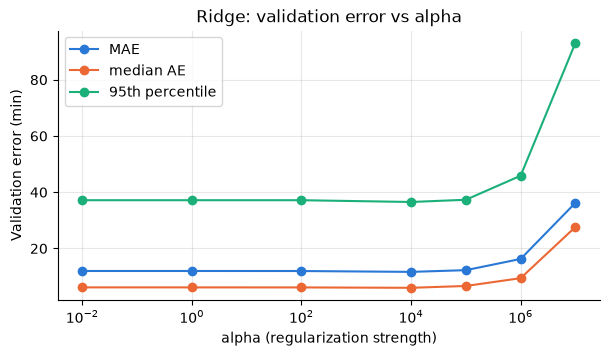

Selected alpha: 10000


In [5]:
ALPHAS = [1e-2, 1e0, 1e2, 1e4, 1e5, 1e6, 1e7]

rows = []
for alpha in ALPHAS:
    ridge.set_params(model__alpha=alpha)
    ridge.fit(X_train, y_train)
    rows.append({"alpha": alpha, **evaluate(y_val, ridge.predict(X_val), val_segment)})
alpha_search = pd.DataFrame(rows).set_index("alpha")
display(alpha_search.round(3))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(alpha_search.index, alpha_search["MAE (min)"], marker="o", label="MAE")
ax.plot(alpha_search.index, alpha_search["median AE (min)"], marker="o", label="median AE")
ax.plot(alpha_search.index, alpha_search["P95 AE (min)"], marker="o", label="95th percentile")
ax.set_xscale("log")
ax.set_xlabel("alpha (regularization strength)")
ax.set_ylabel("Validation error (min)")
ax.set_title("Ridge: validation error vs alpha")
ax.legend()
plt.show()

best_ridge_alpha = alpha_search["MAE (min)"].idxmin()
ridge.set_params(model__alpha=best_ridge_alpha).fit(X_train, y_train)
ridge_pred = ridge.predict(X_val)
print(f"Selected alpha: {best_ridge_alpha:g}")

The error barely moves over several orders of magnitude of $\alpha$, including the smallest values that are practically an ordinary least-squares regression: with 1.4 million training rows for ~250 weights, the data largely dominates the penalty. Regularization matters when there are few rows per weight; here only a very strong penalty degrades the model.

### 4.2 Linear model, MAE loss: α

In [6]:
SGD_ALPHAS = [1e-7, 1e-6, 1e-5, 1e-4]

rows, mae_models = [], {}
for alpha in SGD_ALPHAS:
    model = make_sgd_pipeline(alpha, **MAE_LOSS)
    model.fit(X_train, y_train / SECONDS_PER_HOUR)   # target in hours
    mae_models[alpha] = model
    rows.append({"alpha": alpha, "epochs": model.named_steps["model"].n_iter_,
                 **evaluate(y_val, model.predict(X_val) * SECONDS_PER_HOUR, val_segment)})
mae_search = pd.DataFrame(rows).set_index("alpha")
display(mae_search.round(3))

best_mae_alpha = mae_search["MAE (min)"].idxmin()
mae_model = mae_models[best_mae_alpha]
mae_pred = mae_model.predict(X_val) * SECONDS_PER_HOUR   # back to seconds
print(f"Selected alpha: {best_mae_alpha:g}")

,epochs,MAE (min),median AE (min),P95 AE (min),MAE pre (min),MAE cruise (min),MAE post (min)
alpha,,,,,,,
1.000000e-07,9,8.112,3.027,16.047,14.374,7.260,3.553
1.000000e-06,8,8.112,3.027,16.057,14.375,7.260,3.553
1.000000e-05,9,8.112,3.026,16.047,14.375,7.260,3.552
1.000000e-04,8,8.112,3.026,16.059,14.377,7.261,3.551


Selected alpha: 1e-05


As for the Ridge, α barely matters over this range: the penalty is negligible compared with the data, and tuning α mostly checks that the penalty is not too strong.

### 4.3 Linear model, Huber loss: α and δ

δ moves the Huber loss between the two extremes: with a small δ, almost every error is "large" and the loss behaves like an MAE (scaled by δ); with a large δ, almost every error is "small" and it behaves like an MSE. Both hyperparameters are tuned together, on a grid.

Validation MAE (min) for each (δ, alpha):


alpha,1.000000e-07,1.000000e-06,1.000000e-05,1.000000e-04
δ (min),,,,
1,16.45,16.46,16.58,17.26
5,9.07,9.07,9.08,9.24
15,8.34,8.34,8.34,8.39
60,8.96,8.96,8.96,8.97


Epochs before SGD stops (tol):


alpha,1.000000e-07,1.000000e-06,1.000000e-05,1.000000e-04
δ (min),,,,
1,20,20,20,21
5,11,11,11,11
15,8,8,8,8
60,8,8,8,8


Selected: δ = 15 min, alpha = 1e-07


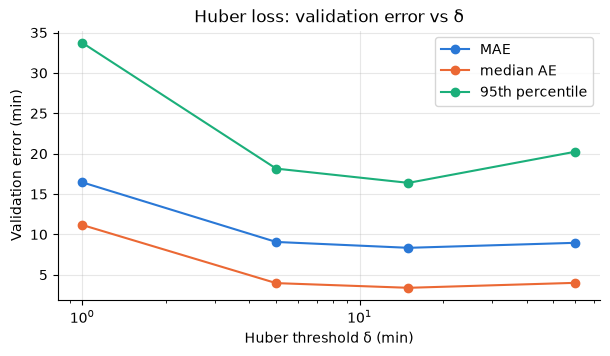

In [7]:
HUBER_DELTAS_MIN = [1, 5, 15, 60]

rows, huber_predictions = [], {}
for delta_min in HUBER_DELTAS_MIN:
    for alpha in SGD_ALPHAS:
        model = make_sgd_pipeline(alpha, loss="huber", epsilon=delta_min / 60)
        model.fit(X_train, y_train / SECONDS_PER_HOUR)
        prediction = model.predict(X_val) * SECONDS_PER_HOUR
        huber_predictions[(delta_min, alpha)] = prediction
        rows.append({"δ (min)": delta_min, "alpha": alpha, "epochs": model.named_steps["model"].n_iter_,
                     **evaluate(y_val, prediction, val_segment)})
huber_search = pd.DataFrame(rows)
print("Validation MAE (min) for each (δ, alpha):")
display(huber_search.pivot(index="δ (min)", columns="alpha", values="MAE (min)").round(2))
print("Epochs before SGD stops (tol):")
display(huber_search.pivot(index="δ (min)", columns="alpha", values="epochs"))

best_huber = huber_search.loc[huber_search["MAE (min)"].idxmin()]
best_delta_min, best_huber_alpha = best_huber["δ (min)"], best_huber["alpha"]
huber_pred = huber_predictions[(best_delta_min, best_huber_alpha)]
print(f"Selected: δ = {best_delta_min:g} min, alpha = {best_huber_alpha:g}")

# All the metrics as a function of δ, at the selected alpha
by_delta = huber_search[huber_search["alpha"] == best_huber_alpha].set_index("δ (min)")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(by_delta.index, by_delta["MAE (min)"], marker="o", label="MAE")
ax.plot(by_delta.index, by_delta["median AE (min)"], marker="o", label="median AE")
ax.plot(by_delta.index, by_delta["P95 AE (min)"], marker="o", label="95th percentile")
ax.set_xscale("log")
ax.set_xlabel("Huber threshold δ (min)")
ax.set_ylabel("Validation error (min)")
ax.set_title("Huber loss: validation error vs δ")
ax.legend()
plt.show()

- **δ = 15 minutes** gives the best Huber model (MAE ≈ 8.3 minutes); as for the other candidates, α barely matters.
- With a **large δ (60 minutes)**, most errors fall in the quadratic part and the Huber loss moves towards the MSE and the MAE degrades (about 9.0 minutes).
- With a **very small δ (1 minute)**, the model is *bad*, although the loss is then close to an MAE. This is an optimization effect: beyond δ, the gradient of the Huber loss is ±δ instead of ±1 for the MAE, so with δ = 1 min = 0.017 h, SGD takes tiny steps: the loss improves by less than `tol` from one epoch to the next, and the training stops after about 20 epochs, far from the minimum.

## 5. Comparison of the tuned candidates and selection

The three tuned candidates, with the two baselines as references. The decision is made on the **MAE**; the median, the 95th percentile and the MAE of each segment are checked as guardrails, and the paired bootstrap tells whether the differences with the best candidate are larger than the noise.

In [8]:
tuned_predictions = {
    "Ridge (MSE loss)": ridge_pred,
    "Linear, Huber loss": huber_pred,
    "Linear, MAE loss": mae_pred,
}
for name, prediction in tuned_predictions.items():
    results[name] = evaluate(y_val, prediction, val_segment)
display(pd.DataFrame(results).T.round(2))

best_candidate = min(tuned_predictions, key=lambda name: results[name]["MAE (min)"])
print(f"Lowest validation MAE: {best_candidate}")
print("Paired bootstrap against this candidate (a positive difference means a worse MAE):")
display(bootstrap_comparison(y_val, tuned_predictions, val_flight, reference=best_candidate))

,MAE (min),median AE (min),P95 AE (min),MAE pre (min),MAE cruise (min),MAE post (min)
Constant (train median),44.01,23.52,149.03,78.59,34.22,29.01
Naive: distance / speed,16.06,8.71,42.53,30.68,13.59,6.37
Ridge (MSE loss),11.66,6.00,36.52,18.06,9.22,10.15
"Linear, Huber loss",8.34,3.39,16.39,14.37,7.44,4.11
"Linear, MAE loss",8.11,3.03,16.05,14.37,7.26,3.55


Lowest validation MAE: Linear, MAE loss
Paired bootstrap against this candidate (a positive difference means a worse MAE):


,MAE (min),MAE 95 % CI,difference vs reference (min),difference 95 % CI
Ridge (MSE loss),11.66,"[11.06, 12.31]",3.55,"[+3.36, +3.75]"
"Linear, Huber loss",8.34,"[7.68, 9.06]",0.23,"[+0.19, +0.26]"
"Linear, MAE loss",8.11,"[7.45, 8.84]",0.0,"[+0.00, +0.00]"


**Decision: the linear model with the MAE loss is selected.**
- **Decision metric:** it has the lowest MAE (8.1 minutes). The paired bootstrap shows that both differences are real: +0.23 minute for the Huber model (interval about [+0.19, +0.26]) and +3.6 minutes for the Ridge (about [+3.4, +3.8]).
- **Guardrails:** it also has the lowest median and the lowest 95th percentile, and the lowest MAE in every segment (tied with the Huber model before the cruise). No guardrail contradicts the decision.
- **Why the Ridge falls behind:** its 95th percentile is more than twice larger (about 37 vs 16 minutes). The squared loss lets a handful of huge errors (long flights, impossible labels) pull all the predictions, which degrades the typical errors *and* most of the large ones. Under an RMSE, the Ridge would win instead: the metric decides, which is why it was fixed before the experiments.

## 6. Analysis of the selected model: linear, MAE loss

From now on, the analyses focus on the selected model.

### 6.1 What the model learnt

Since the features are standardized, each coefficient reads as: *"when this feature increases by one standard deviation, all others being fixed, the predicted remaining time changes by this many minutes"* (the model is trained in hours, so the coefficients are multiplied by 60).

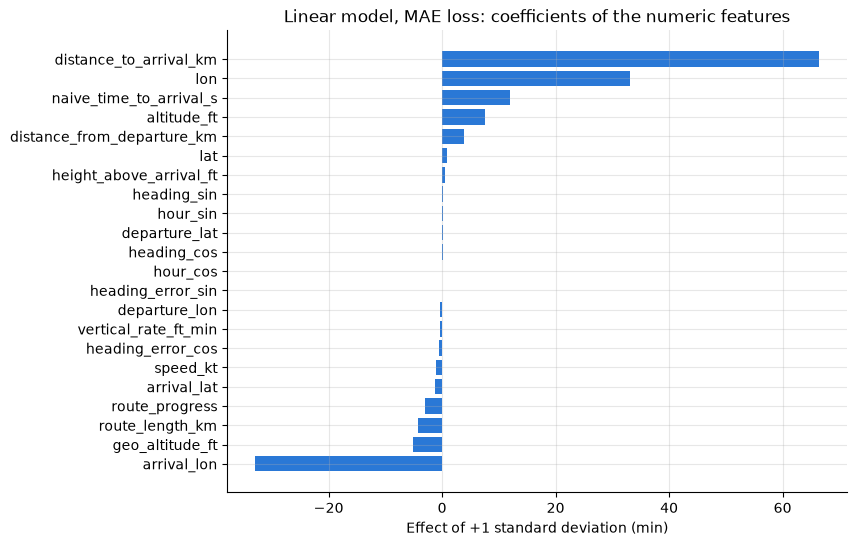

Arrival-airport effects: from 14.6 min (LEMG) to 27.0 min (LTFM)


In [9]:
feature_names = mae_model.named_steps["preprocess"].get_feature_names_out()
coefficients = pd.Series(mae_model.named_steps["model"].coef_ * 60, index=feature_names)
numeric_coefficients = (
    coefficients[[f"numeric__{name}" for name in NUMERIC_FEATURES]]
    .rename(lambda name: name.removeprefix("numeric__"))
).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(numeric_coefficients.index, numeric_coefficients.values)
ax.set_xlabel("Effect of +1 standard deviation (min)")
ax.set_title("Linear model, MAE loss: coefficients of the numeric features")
plt.show()

arrival_effects = coefficients[[name for name in feature_names
                                if name.startswith("airports__estArrivalAirport_")]].sort_values()
print(f"Arrival-airport effects: from {arrival_effects.iloc[0]:.1f} min "
      f"({arrival_effects.index[0].removeprefix('airports__estArrivalAirport_')}) "
      f"to {arrival_effects.iloc[-1]:.1f} min "
      f"({arrival_effects.index[-1].removeprefix('airports__estArrivalAirport_')})")

- **The distance to arrival dominates** (about +66 minutes per standard deviation): the model essentially learns "remaining distance / an average speed", corrected by the other features. The naive time to arrival adds about +12 minutes per standard deviation.
- **The longitude of the aircraft and the longitude of its arrival airport have large weights of opposite signs** (about +33 and −33 minutes). Together, they encode the east-west *difference* between the aircraft and its destination: for the same distance, the model predicts a longer remaining time when the aircraft still has to fly west. This is consistent with the jet streams, which slow down westbound flights.
- **The two altitudes also have weights of opposite signs** (about +7.5 and −5 minutes): they are redundant features.
- **The airport one-hot spreads the arrival airports over about 12 minutes**, from Málaga (LEMG) to Istanbul (LTFM): large hubs, with longer approach procedures and holding patterns, get a longer predicted remaining time.

### 6.2 What each group of features brings (ablation)

Same model, same α, with some features removed: the change in the metrics measures what they bring, and the paired bootstrap whether it is real.

In [10]:
variants = {
    "all features": (NUMERIC_FEATURES, CATEGORICAL_FEATURES),
    "without the airport one-hot": (NUMERIC_FEATURES, []),
    "without the naive time to arrival": (
        [f for f in NUMERIC_FEATURES if f != "naive_time_to_arrival_s"], CATEGORICAL_FEATURES
    ),
    "distance to arrival only": (["distance_to_arrival_km"], []),
}
ablation_predictions = {}
for name, (numeric, categorical) in variants.items():
    model = Pipeline([
        ("preprocess", make_preprocessor(numeric, categorical)),
        ("model", make_sgd_regressor(best_mae_alpha, **MAE_LOSS)),
    ])
    model.fit(X_train, y_train / SECONDS_PER_HOUR)
    ablation_predictions[name] = model.predict(X_val) * SECONDS_PER_HOUR

display(pd.DataFrame({name: evaluate(y_val, pred, val_segment)
                      for name, pred in ablation_predictions.items()}).T.round(2))
display(bootstrap_comparison(y_val, ablation_predictions, val_flight, reference="all features"))

,MAE (min),median AE (min),P95 AE (min),MAE pre (min),MAE cruise (min),MAE post (min)
all features,8.11,3.03,16.05,14.37,7.26,3.55
without the airport one-hot,8.40,3.20,17.07,14.82,7.61,3.55
without the naive time to arrival,8.32,3.24,16.21,14.41,7.40,4.04
distance to arrival only,10.10,4.29,26.54,17.67,9.02,4.70


,MAE (min),MAE 95 % CI,difference vs reference (min),difference 95 % CI
all features,8.11,"[7.45, 8.84]",0.0,"[+0.00, +0.00]"
without the airport one-hot,8.4,"[7.74, 9.11]",0.29,"[+0.25, +0.32]"
without the naive time to arrival,8.32,"[7.67, 9.03]",0.2,"[+0.15, +0.25]"
distance to arrival only,10.1,"[9.45, 10.79]",1.99,"[+1.82, +2.16]"


- **The airport one-hot brings a real gain:** removing it costs about +0.3 minute of MAE (interval about [+0.25, +0.32]) and degrades the 95th percentile. The airport coordinates cannot replace it in a linear model: the one-hot gives each frequent airport its own offset.
- **The naive time to arrival brings a real gain too:** about +0.2 minute without it (interval about [+0.15, +0.25]), mostly after the cruise, where the ratio distance / speed is reliable and that a linear model cannot build by itself.
- **The distance alone is far from enough** (about +2 minutes): the other features carry the rest (speed, phase, geography).

### 6.3 Is the model overfitting?

Two checks:
1. compare the training and validation errors;
2. follow the errors along the training: if the validation error starts going up again while the training error keeps going down, the model is overfitting, and **early stopping** would help.

Train MAE: 8.33 min, validation MAE: 8.11 min


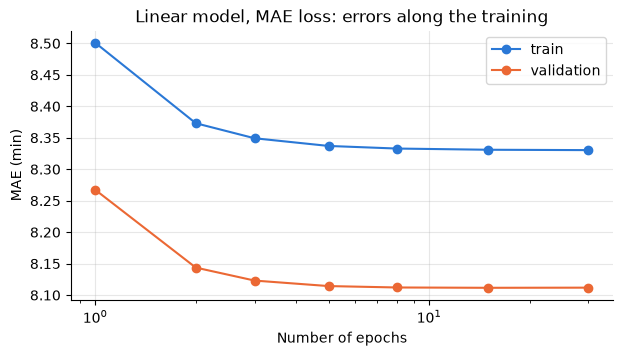

With tol=1e-4 (the setting used above), SGD stops by itself after 9 epochs.


In [11]:
print(f"Train MAE: {mean_absolute_error(y_train, mae_model.predict(X_train) * SECONDS_PER_HOUR) / 60:.2f} min, "
      f"validation MAE: {mean_absolute_error(y_val, mae_pred) / 60:.2f} min")

# Errors as a function of the number of epochs (tol=None: exactly `epochs` passes)
rows = []
for epochs in [1, 2, 3, 5, 8, 15, 30]:
    model = make_sgd_pipeline(best_mae_alpha, **MAE_LOSS)
    model.set_params(model__max_iter=epochs, model__tol=None)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)  # stopping early on purpose
        model.fit(X_train, y_train / SECONDS_PER_HOUR)
    rows.append({
        "epochs": epochs,
        "train MAE (min)": mean_absolute_error(y_train, model.predict(X_train) * SECONDS_PER_HOUR) / 60,
        "validation MAE (min)": mean_absolute_error(y_val, model.predict(X_val) * SECONDS_PER_HOUR) / 60,
    })
epoch_curve = pd.DataFrame(rows).set_index("epochs")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(epoch_curve.index, epoch_curve["train MAE (min)"], marker="o", label="train")
ax.plot(epoch_curve.index, epoch_curve["validation MAE (min)"], marker="o", label="validation")
ax.set_xscale("log")
ax.set_xlabel("Number of epochs")
ax.set_ylabel("MAE (min)")
ax.set_title("Linear model, MAE loss: errors along the training")
ax.legend()
plt.show()
print(f"With tol=1e-4 (the setting used above), SGD stops by itself after "
      f"{mae_model.named_steps['model'].n_iter_} epochs.")

- The training and validation errors are almost identical: **no overfitting**. With ~250 weights for 1.4 million rows, a linear model cannot memorize the data. The opposite problem is visible instead, **underfitting**: the model is too simple for the data, which is why its error stays high.
- The validation error goes down, then stays flat, and never goes up again: **early stopping is useless here**.

### 6.4 Where does the model fail?

Error of the selected model by flight segment and, for information, by remaining time, next to the other tuned candidates and the naive baseline.

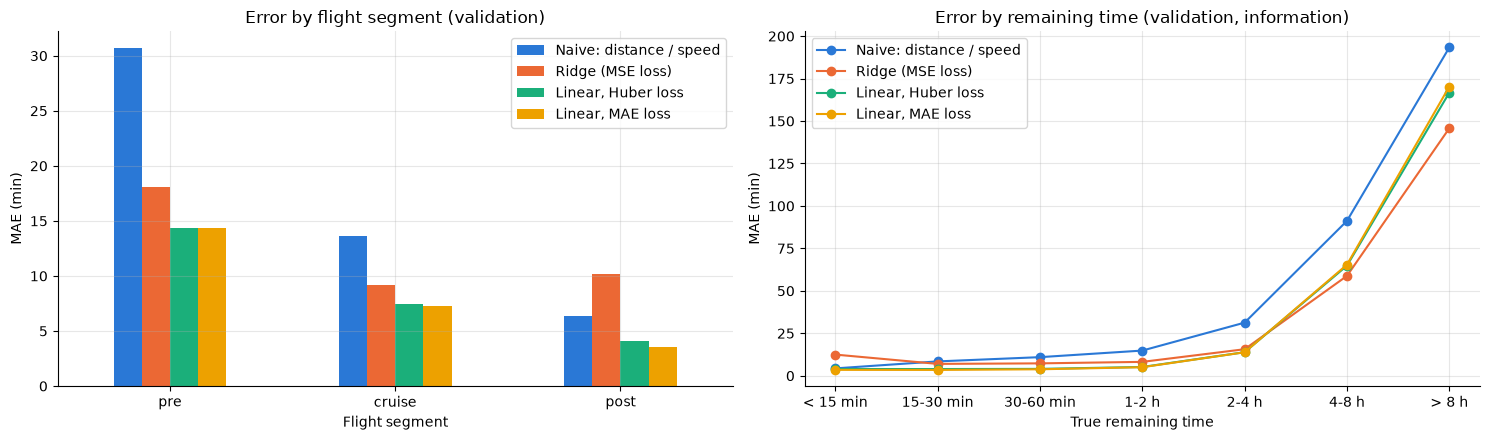

,Naive: distance / speed,Ridge (MSE loss),"Linear, Huber loss","Linear, MAE loss"
phase_of_flight,,,,
pre,30.68,18.06,14.37,14.37
cruise,13.59,9.22,7.44,7.26
post,6.37,10.15,4.11,3.55


In [12]:
compared = {"Naive: distance / speed": validation["naive_time_to_arrival_s"].to_numpy(), **tuned_predictions}
remaining_bins = pd.cut(y_val / 60, bins=REMAINING_BINS_MIN, labels=REMAINING_LABELS, include_lowest=True)
absolute_errors = pd.DataFrame(
    {name: np.abs(pred - y_val.to_numpy()) / 60 for name, pred in compared.items()},
    index=y_val.index,
)
by_remaining = absolute_errors.groupby(remaining_bins, observed=True).mean()
by_segment_part1 = absolute_errors.groupby(val_segment).mean().loc[SEGMENTS]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
by_segment_part1.plot.bar(ax=axes[0], rot=0)
axes[0].set_xlabel("Flight segment")
axes[0].set_ylabel("MAE (min)")
axes[0].set_title("Error by flight segment (validation)")
by_remaining.plot(ax=axes[1], marker="o")
axes[1].set_xlabel("True remaining time")
axes[1].set_ylabel("MAE (min)")
axes[1].set_title("Error by remaining time (validation, information)")
plt.tight_layout()
plt.show()
display(by_segment_part1.round(2))

- **Ridge sacrifices the end of the flights:** after the cruise (`post`), it is off by ~10 minutes, worse than the naive estimate, while the selected model is off by ~3.5 minutes.
- **Below 2 hours of remaining time, the selected model is accurate** (3 to 5 minutes of error).
- **All the linear models fail before the cruise** (`pre`: 14 minutes at best, including the level-offs during the climb and the flights whose beginning is missing) and on long remaining times (errors of one to three hours beyond 4 h). A single set of weights cannot fit both the climb and the approach.

In [13]:
# Information only: errors by remaining time
mae_table, relative_table = remaining_time_report(y_val, compared)
print("MAE by remaining time (min), information only")
display(mae_table.round(1))
print("Relative error (%) = MAE / mean true remaining time of the group, information only")
display(relative_table.round(1))

MAE by remaining time (min), information only


,share of rows (%),Naive: distance / speed,Ridge (MSE loss),"Linear, Huber loss","Linear, MAE loss"
< 15 min,14.9,4.3,12.5,4.0,3.5
15-30 min,19.3,8.4,7.0,3.9,3.4
30-60 min,31.3,10.9,7.3,4.0,3.8
1-2 h,22.0,14.8,8.2,5.2,5.0
2-4 h,9.1,31.3,15.6,13.9,13.8
4-8 h,2.5,91.2,58.8,64.8,65.4
> 8 h,1.0,193.3,145.7,166.7,170.3


Relative error (%) = MAE / mean true remaining time of the group, information only


,Naive: distance / speed,Ridge (MSE loss),"Linear, Huber loss","Linear, MAE loss"
< 15 min,58.3,167.5,53.1,46.6
15-30 min,36.8,30.4,17.1,14.9
30-60 min,25.4,16.9,9.4,8.8
1-2 h,17.6,9.7,6.1,6.0
2-4 h,19.8,9.9,8.8,8.8
4-8 h,27.3,17.6,19.4,19.6
> 8 h,31.5,23.8,27.2,27.8


In [14]:
# Why does the error explode for long remaining times? (selected model)
error_min = (mae_pred - y_val.to_numpy()) / 60
long_horizon = (y_val > 4 * SECONDS_PER_HOUR).to_numpy()
# Flights with a suspicious label, with the criteria of section 6.5
suspicious_flights = flag_suspicious_labels(flight_errors(validation), flight_errors(train))[0]["suspicious label"]
suspicious_row = suspicious_flights.reindex(pd.MultiIndex.from_frame(validation[FLIGHT_KEY])).to_numpy()
print(f"Rows more than 4 h from arrival: {long_horizon.mean():.1%} of the rows, but "
      f"{np.abs(error_min[long_horizon]).sum() / np.abs(error_min).sum():.0%} of the total absolute error")
print(f"Mean signed error beyond 4 h: {error_min[long_horizon].mean():+.0f} min "
      f"(negative = the model underestimates)")
print(f"Rows of the flights with a suspicious label (section 6.5): {suspicious_row.mean():.1%} of all the rows, "
      f"{suspicious_row[long_horizon].mean():.0%} of the rows beyond 4 h")
print(f"MAE beyond 4 h: {np.abs(error_min[long_horizon]).mean():.0f} min, "
      f"{np.abs(error_min[long_horizon & ~suspicious_row]).mean():.0f} min without these flights")

Rows more than 4 h from arrival: 3.5% of the rows, but 42% of the total absolute error
Mean signed error beyond 4 h: -71 min (negative = the model underestimates)
Rows of the flights with a suspicious label (section 6.5): 4.0% of all the rows, 22% of the rows beyond 4 h
MAE beyond 4 h: 96 min, 40 min without these flights


**Why does the error explode for long remaining times?** Three effects add up:
1. **A harder problem.** Several hours before the landing, the uncertainty piles up (winds, routing, holding patterns): the error naturally grows with the horizon. The relative error shows how far this explains it: it is lowest between 30 minutes and 4 hours (6 to 9 % of the remaining time: the 14-minute error between 2 and 4 hours is, relatively, as good as the 4-minute error between 30 and 60 minutes), but it doubles beyond 4 hours. The absolute error therefore grows *faster* than the horizon: the two effects below are at work. (Very close to the landing, the relative error is high again only because the remaining time itself is a few minutes.)
2. **Few examples, and a model that leans on the bulk of the data.** Only a few percent of the rows are more than 4 hours from the arrival (long-haul flights, under-represented by a single day of data). The MAE loss targets the median, so the linear model fits the short flights and **systematically underestimates** long remaining times (negative mean error above).
3. **Label errors weigh more far from the arrival.** Some labels are physically impossible (criteria of section 6.5: same departure and arrival airport, or an implied average speed far from that of the flights of the same route length). These are typically several flights of the same aircraft merged into one OpenSky record, or a wrong estimated arrival airport: the label is then wrong by several hours. These flights make 4 % of all the rows but 22 % of the rows beyond 4 hours, and without them the MAE beyond 4 hours drops from 96 to 40 minutes. The MAE loss is robust to them in training, but they inflate the measured error.

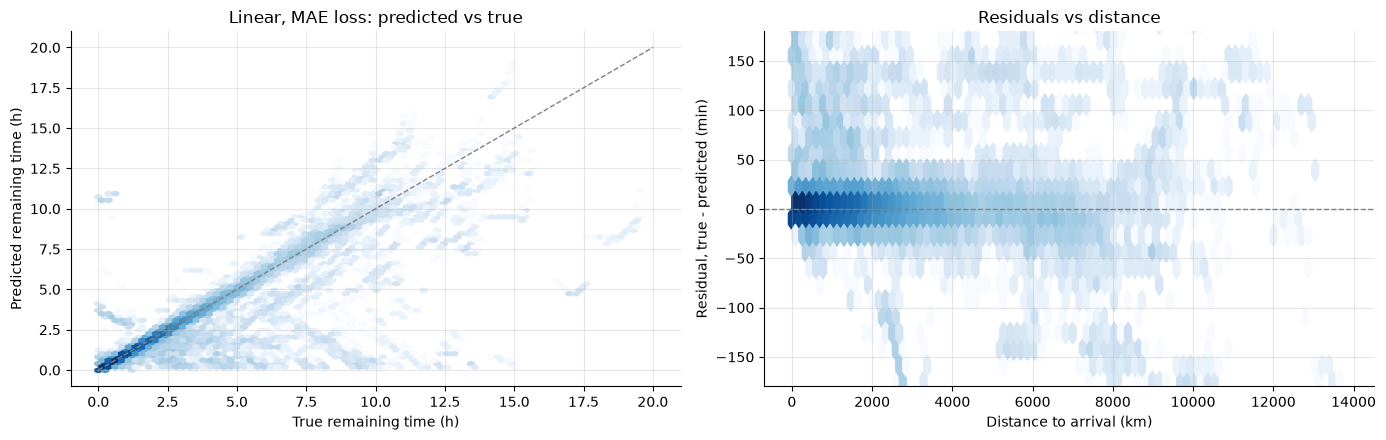

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hexbin(y_val / 3600, mae_pred / 3600, gridsize=80, bins="log", cmap="Blues", mincnt=1)
axes[0].plot([0, 20], [0, 20], color="gray", linestyle="--", linewidth=1)
axes[0].set_xlabel("True remaining time (h)")
axes[0].set_ylabel("Predicted remaining time (h)")
axes[0].set_title("Linear, MAE loss: predicted vs true")

residual_min = (y_val.to_numpy() - mae_pred) / 60
axes[1].hexbin(validation["distance_to_arrival_km"], residual_min, gridsize=80, bins="log",
               cmap="Blues", mincnt=1)
axes[1].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[1].set_ylim(-180, 180)
axes[1].set_xlabel("Distance to arrival (km)")
axes[1].set_ylabel("Residual, true - predicted (min)")
axes[1].set_title("Residuals vs distance")
plt.tight_layout()
plt.show()

Most points lie on the diagonal, but some points close to their destination still have a long time to fly (large positive residuals at short distance): holding patterns, flights that do not go straight to their destination, or noise in the label. A linear function of the distance cannot capture them.

### 6.5 The worst-predicted flights

The errors are summed up **by flight**: if OpenSky merged two flights of the same aircraft into one record, or estimated a wrong arrival airport, all the points of the flight get an impossible label. Three questions: are the errors concentrated on a few flights? What do these flights look like? Is their label plausible?

**Checking a label.** The remaining time at the first sampled point (just after the take-off) is close to the duration of the flight, so *route length / this time* is the **average speed implied by the label**. It is compared with the typical speed of the flights of the same route length (median over the training flights, by deciles of route length: from ~250 kt on short routes to ~450 kt on long-haul routes). A label is flagged as **suspicious** when:
- the departure and arrival airports are the same (a return to the departure airport, a local flight): the distance to the arrival does not describe the flight;
- the implied speed is below 0.6 times the typical speed: the label is far too long (for example several flights merged into one record, the ground time of the stopover included);
- the implied speed is above 1.6 times the typical speed: the label is far too short (for example a wrong arrival airport).

The two thresholds flag about 2 % and 0.7 % of the training flights (different airports): only flights far from normal are flagged. The functions are in `src/opensky_eta/evaluation.py`.

Share of the total error made on the worst flights (Linear, MAE loss):


,worst 1% of the flights,worst 5% of the flights,worst 10% of the flights
share of the total error,0.264,0.521,0.597


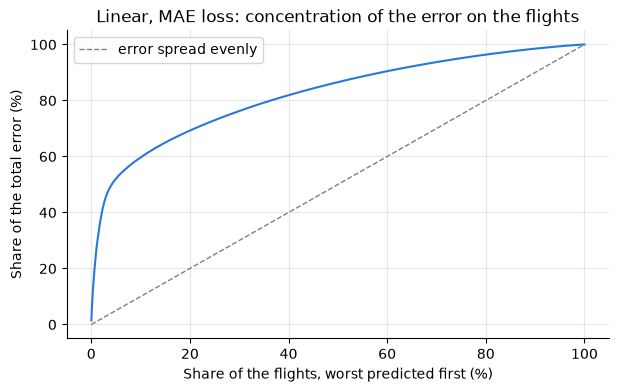

The 15 worst-predicted validation flights:


,,,departure,arrival,route_length_km,duration (h),implied_speed_kt,speed / typical speed,suspicious label,"Linear, MAE loss: MAE (min)","Linear, MAE loss: mean signed error (min)"
icao24,firstSeen,lastSeen,,,,,,,,,
ac9b82,1.772341e+09,1772343285,KFSD,SD62,7593.27,0.59,6965.61,15.44,True,621.40,621.40
8a06f0,1.772335e+09,1772397955,WMKK,YPPH,4140.16,17.56,127.33,0.28,True,400.03,-395.36
76cccb,1.772331e+09,1772401375,YMML,VHHH,7412.32,19.56,204.63,0.45,True,331.80,-330.61
4b9e05,1.772370e+09,1772401274,EDDF,LTFJ,1900.51,8.56,119.84,0.31,True,323.43,-323.42
7c77f9,1.772352e+09,1772398880,YMML,YSSY,705.61,12.92,29.49,0.08,True,305.48,-303.21
86d9b0,1.772360e+09,1772393911,RJAA,RJTT,59.57,9.37,3.43,0.01,True,304.68,-295.50
48af10,1.772349e+09,1772394598,EPWA,EPWA,0.00,12.52,0.00,0.00,True,300.97,-299.79
76cd03,1.772286e+09,1772376228,YBBN,WSAP,6150.98,13.63,243.65,0.54,True,288.97,-284.04
a2f5b8,1.772356e+09,1772398519,KCVG,67KY,28.61,11.83,1.31,0.01,True,277.47,-275.24


Suspicious labels:


,flights,share of the flights,"Linear, MAE loss: share of its worst 1 %","Linear, MAE loss: share of its total error"
same departure and arrival airport,76.0,0.015,0.385,0.160
implied speed < 0.6 x typical,84.0,0.016,0.423,0.199
implied speed > 1.6 x typical,46.0,0.009,0.115,0.043
suspicious label,206.0,0.040,0.923,0.402


Information only: MAE 8.11 min on all the flights, 5.06 min without the suspicious labels
Typical speed by decile of route length: from 253 kt to 451 kt
Training flights (different airports) with an implied speed < 0.6 x typical: 1.8%
Training flights (different airports) with an implied speed > 1.6 x typical: 0.7%


In [16]:
train_flights = flight_errors(train)
val_flights = flight_errors(validation, {"Linear, MAE loss": mae_pred})
flags, speed_ratio = flag_suspicious_labels(val_flights, train_flights)
flight_mae = val_flights["Linear, MAE loss: MAE (min)"]

concentration, curve = error_concentration(flight_mae)
print("Share of the total error made on the worst flights (Linear, MAE loss):")
display(concentration.round(3).to_frame("share of the total error").T)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(curve) + 1) / len(curve) * 100, curve * 100)
ax.plot([0, 100], [0, 100], color="gray", linestyle="--", linewidth=1, label="error spread evenly")
ax.set_xlabel("Share of the flights, worst predicted first (%)")
ax.set_ylabel("Share of the total error (%)")
ax.set_title("Linear, MAE loss: concentration of the error on the flights")
ax.legend()
plt.show()

print("The 15 worst-predicted validation flights:")
worst = (val_flights.assign(**{"speed / typical speed": speed_ratio, "suspicious label": flags["suspicious label"]})
         .nlargest(15, "Linear, MAE loss: MAE (min)"))
columns = ["departure", "arrival", "route_length_km", "first_remaining_h", "implied_speed_kt", "speed / typical speed",
           "suspicious label", "Linear, MAE loss: MAE (min)", "Linear, MAE loss: mean signed error (min)"]
display(worst[columns].rename(columns={"first_remaining_h": "duration (h)"}).round(2))

print("Suspicious labels:")
display(suspicious_label_report(flags, {"Linear, MAE loss": flight_mae}).round(3))
print(f"Information only: MAE {flight_mae.mean():.2f} min on all the flights, "
      f"{flight_mae[~flags['suspicious label']].mean():.2f} min without the suspicious labels")

# Typical speeds and thresholds of the speed check, on the training flights (its reference)
train_flags, train_ratio = flag_suspicious_labels(train_flights, train_flights)
different_airports = ~train_flags["same departure and arrival airport"]
typical_speed_kt = (train_flights["implied_speed_kt"] / train_ratio)[different_airports]
print(f"Typical speed by decile of route length: from {typical_speed_kt.min():.0f} kt "
      f"to {typical_speed_kt.max():.0f} kt")
for column in train_flags.columns[1:3]:
    print(f"Training flights (different airports) with an {column}: "
          f"{train_flags.loc[different_airports, column].mean():.1%}")

- **The error is very concentrated on a few flights:** the 1 % worst-predicted flights (51 flights) make 26 % of the total error, the 5 % worst more than half (52 %).
- **These flights have impossible labels.** All the 15 worst flights are flagged as suspicious, for example:
  - Kuala Lumpur → Perth (WMKK → YPPH), a flight of about 5.5 hours, with a label of 17.6 hours (an average speed of 127 kt);
  - Sioux Falls → SD62, 7,600 km in 36 minutes: the estimated arrival airport (or its coordinates) is wrong;
  - Narita → Narita, Warsaw → Warsaw, Rome → Rome…: the same departure and arrival airport, with labels of 6 to 15 hours, very likely several flights of the same aircraft merged into one OpenSky record.

  For the labels that are too long, the model predicts much less time (large negative signed errors): it predicts a normal flight, the label describes several. For Sioux Falls → SD62, it is the opposite: the model predicts a long flight towards a wrong airport far away.
- **4 % of the flights have a suspicious label, but they make 40 % of the total error,** and 92 % of the 1 % worst flights. Without them, the MAE would be 5.1 minutes instead of 8.1.
- **Consequences.** A large part of the remaining error comes from the data, not from the model. These flights are also in the training set, where they can bias the model: detecting them in notebook 02 (merged records, wrong airports) is the most promising way to improve both the training and the evaluation. It also confirms the choice of the MAE loss: with a squared loss, these few flights weigh even more (section 5).

**End of part 1.** The best single model is the linear model trained with the MAE loss (~8 minutes of error on average). It does not overfit, but it underfits: the errors strongly depend on the phase of flight. A single set of weights has to describe a climb, a cruise and an approach at the same time, which motivates part 2.

# Part 2 — One linear MAE model per flight segment

## 7. The idea and its assumption

Instead of one set of weights for the whole flight, we train **three linear models**, one per flight segment (the grouping used for the sampling in notebook 02):

| Segment | Phases | State vectors per flight |
|---|---|---|
| `pre` | climb, est_climb | 15 |
| `cruise` | cruise, short cruise | 30 |
| `post` | descent, est_descent | 15 |

Each model is still linear, but the whole is **piecewise linear**: the weight of the distance, of the speed or of an airport can differ between the climb, the cruise and the descent.

> **Assumption.** As stated in the introduction, the phase of flight is assumed to be known at any time (for live flights, from the flight plan for example). Each state vector is routed to its model with `phase_of_flight`.

In [17]:
display(pd.DataFrame({
    "train rows": train_segment.value_counts(),
    "validation rows": val_segment.value_counts(),
}).loc[SEGMENTS])

,train rows,validation rows
phase_of_flight,,
pre,359850,77115
cruise,719700,154230
post,359850,77115


## 8. What training per segment changes for the preprocessing

A model trained on one segment only sees the rows of that segment. Everything the preprocessing *learns from the data* is affected: the means and standard deviations of the scaler, and the list of frequent airports of the encoder.

### 8.1 Scaling

In [18]:
in_train_segment = {segment: (train_segment == segment).to_numpy() for segment in SEGMENTS}

# Standard deviation of each feature within a segment, relative to its global standard deviation
spread = pd.DataFrame({
    segment: X_train.loc[in_train_segment[segment], NUMERIC_FEATURES].std() for segment in SEGMENTS
}).div(X_train[NUMERIC_FEATURES].std(), axis=0)
display(spread.loc[["distance_to_arrival_km", "naive_time_to_arrival_s", "route_progress",
                    "altitude_ft", "speed_kt", "vertical_rate_ft_min"]].round(2)
        .rename_axis("std within segment / global std"))

# The same raw value gets a different standardized value
distance = X_train["distance_to_arrival_km"]
distance_post = distance[in_train_segment["post"]]
print(f"An aircraft 200 km from its arrival airport: z = {(200 - distance.mean()) / distance.std():+.2f} "
      f"with the global scaler, z = {(200 - distance_post.mean()) / distance_post.std():+.2f} "
      f"with a scaler fitted on the descent only")

,pre,cruise,post
std within segment / global std,,,
distance_to_arrival_km,1.39,0.82,0.20
naive_time_to_arrival_s,1.46,0.69,0.23
route_progress,0.35,0.60,0.37
altitude_ft,0.90,0.53,0.91
speed_kt,1.00,0.65,1.07
vertical_rate_ft_min,0.83,0.22,0.67


An aircraft 200 km from its arrival airport: z = -0.50 with the global scaler, z = +0.41 with a scaler fitted on the descent only


Within a segment, some features vary much less than over the whole flight (the distance during the descent, the vertical rate during the cruise). A scaler fitted on one segment "zooms" on the range of values of that segment.

Here it can matter for two reasons:
- the **L2 penalty** acts on the weights of the scaled features, so the scaling decides which weights are penalized the most;
- **SGD** converges better when the features of the rows it sees are well spread around 0.

### 8.2 Frequent airports

The encoder keeps an airport if it appears in at least `min_frequency` **rows**. Over the whole flight, a flight has 60 rows, so 3,000 rows = 50 flights. But within a segment a flight only has 15 or 30 rows: the same 3,000 rows then mean 200 or 100 flights.

In [19]:
def count_airport_columns(rows, min_airport_rows):
    """Number of one-hot airport columns of a preprocessor fitted on the given training rows."""
    preprocessor = make_preprocessor(min_airport_rows=min_airport_rows).fit(X_train[rows])
    return sum(name.startswith("airports__") for name in preprocessor.get_feature_names_out())


all_rows = np.ones(len(X_train), dtype=bool)
airport_columns = pd.DataFrame({
    "rows per flight": {"whole flight": POINTS_PER_FLIGHT, **N_POINTS},
    "threshold 3,000 rows": {
        "whole flight": count_airport_columns(all_rows, 3_000),
        **{s: count_airport_columns(in_train_segment[s], 3_000) for s in SEGMENTS},
    },
    "threshold 50 flights": {
        "whole flight": count_airport_columns(all_rows, MIN_AIRPORT_FLIGHTS * POINTS_PER_FLIGHT),
        **{s: count_airport_columns(in_train_segment[s], MIN_AIRPORT_FLIGHTS * N_POINTS[s]) for s in SEGMENTS},
    },
})
display(airport_columns)

,rows per flight,"threshold 3,000 rows",threshold 50 flights
whole flight,60,232,232
pre,15,53,232
cruise,30,123,232
post,15,53,232


With a threshold in rows, the climb and descent models silently lose most of their airport columns: the rare airports are all merged into "infrequent". With a threshold expressed **in flights** (50 flights × the number of rows per flight in the segment), every segment keeps the same airports as the global model.

### 8.3 The label

In [20]:
display((y_train.groupby(train_segment).describe(percentiles=[0.1, 0.5, 0.9]) / 60)
        .loc[SEGMENTS, ["10%", "50%", "90%", "max"]].round(0).rename_axis("remaining time (min)"))

,10%,50%,90%,max
remaining time (min),,,,
pre,39.0,85.0,223.0,1195.0
cruise,25.0,46.0,117.0,1134.0
post,2.0,13.0,27.0,749.0


Each model only has to predict a narrower range of remaining times: mostly a few minutes to an hour after the cruise, much longer before it. A model specialized on the descent no longer has to compromise with the long flights.

### 8.4 Three preprocessing strategies to compare

| Strategy | Scaler and encoder fitted on | Airport threshold |
|---|---|---|
| **A. Shared preprocessor** | all the training rows (the same as the global model) | 3,000 rows = 50 flights |
| **B. Per-segment preprocessor, threshold in flights** | the training rows of the segment | 50 flights × rows per flight in the segment |
| **C. Per-segment preprocessor, threshold in rows** | the training rows of the segment | 3,000 rows (the naive choice) |

## 9. Training one model per segment

For each strategy and each segment: try a few values of α, keep the one with the lowest MAE on the validation rows of that segment (the grid goes down to 10⁻⁹; as in part 1, the MAE barely changes with α, so the exact value selected, sometimes at the edge of the grid, does not matter). The validation rows are then **routed** to the model of their segment, and the three predictions are assembled into one.

In [21]:
SEGMENT_ALPHAS = [1e-9, 1e-8, 1e-7, 1e-6, 1e-5]


def fit_best_segment_model(build_model, X_seg_train, y_seg_train, X_seg_val, y_seg_val):
    """Tries each alpha of SEGMENT_ALPHAS, keeps the model with the lowest validation MAE.

    Selecting each segment model on the MAE of its segment minimizes the global MAE, which is
    a weighted sum of the segment MAEs (weights = share of rows of each segment).
    """
    best = None
    for alpha in SEGMENT_ALPHAS:
        model = build_model(alpha).fit(X_seg_train, y_seg_train / SECONDS_PER_HOUR)
        prediction = model.predict(X_seg_val) * SECONDS_PER_HOUR
        error = mean_absolute_error(y_seg_val, prediction) / 60
        if best is None or error < best["MAE (min)"]:
            best = {"alpha": alpha, "MAE (min)": error, "model": model, "prediction": prediction}
    return best


# Strategy A: one preprocessor fitted on all the training rows, then shared
shared_preprocessor = make_preprocessor().fit(X_train)
X_train_shared = shared_preprocessor.transform(X_train)  # sparse matrices: rows can be selected
X_val_shared = shared_preprocessor.transform(X_val)

STRATEGIES = ["A. shared preprocessor", "B. per segment, threshold in flights",
              "C. per segment, threshold in rows"]
segment_results = {}
for segment in SEGMENTS:
    in_train = in_train_segment[segment]
    in_val = (val_segment == segment).to_numpy()
    y_seg_train, y_seg_val = y_train[in_train], y_val[in_val]

    segment_results[(STRATEGIES[0], segment)] = fit_best_segment_model(
        make_mae_regressor,
        X_train_shared[in_train], y_seg_train, X_val_shared[in_val], y_seg_val,
    )
    segment_results[(STRATEGIES[1], segment)] = fit_best_segment_model(
        lambda alpha: Pipeline([
            ("preprocess", make_preprocessor(min_airport_rows=MIN_AIRPORT_FLIGHTS * N_POINTS[segment])),
            ("model", make_mae_regressor(alpha)),
        ]),
        X_train[in_train], y_seg_train, X_val[in_val], y_seg_val,
    )
    segment_results[(STRATEGIES[2], segment)] = fit_best_segment_model(
        lambda alpha: Pipeline([
            ("preprocess", make_preprocessor(min_airport_rows=3_000)),
            ("model", make_mae_regressor(alpha)),
        ]),
        X_train[in_train], y_seg_train, X_val[in_val], y_seg_val,
    )

# Assemble the predictions: each validation row gets the prediction of its segment's model
segment_predictions = {}
for strategy in STRATEGIES:
    y_pred = np.full(len(y_val), np.nan)
    for segment in SEGMENTS:
        y_pred[(val_segment == segment).to_numpy()] = segment_results[(strategy, segment)]["prediction"]
    assert not np.isnan(y_pred).any(), "every validation row must be predicted exactly once"
    segment_predictions[strategy] = y_pred

display(pd.DataFrame(
    {key: {"alpha": result["alpha"], "MAE (min)": result["MAE (min)"]} for key, result in segment_results.items()}
).T.rename_axis(["strategy", "segment"]).round({"MAE (min)": 2}))

,,alpha,MAE (min)
strategy,segment,,
A. shared preprocessor,pre,1.000000e-07,14.05
"B. per segment, threshold in flights",pre,1.000000e-07,14.04
"C. per segment, threshold in rows",pre,1.000000e-05,14.25
A. shared preprocessor,cruise,1.000000e-08,6.53
"B. per segment, threshold in flights",cruise,1.000000e-09,6.53
"C. per segment, threshold in rows",cruise,1.000000e-05,6.64
A. shared preprocessor,post,1.000000e-07,3.09
"B. per segment, threshold in flights",post,1.000000e-08,2.96
"C. per segment, threshold in rows",post,1.000000e-06,3.07


## 10. Selection of the preprocessing strategy

Each strategy gives a complete model: three segment models, each with its own α, which differ only by their preprocessing. As in part 1, they are compared with the chosen metrics, and the one with the lowest validation MAE is selected. The paired bootstrap over the validation flights tells whether the differences are real.

In [22]:
strategy_results = pd.DataFrame(
    {strategy: evaluate(y_val, prediction, val_segment) for strategy, prediction in segment_predictions.items()}
).T
display(strategy_results.round(2))

best_strategy = strategy_results["MAE (min)"].idxmin()
print(f"Lowest validation MAE: {best_strategy}")
print("Paired bootstrap against this strategy (a positive difference means a worse MAE):")
display(bootstrap_comparison(y_val, segment_predictions, val_flight, reference=best_strategy))

,MAE (min),median AE (min),P95 AE (min),MAE pre (min),MAE cruise (min),MAE post (min)
A. shared preprocessor,7.55,2.63,15.11,14.05,6.53,3.09
"B. per segment, threshold in flights",7.51,2.62,15.13,14.04,6.53,2.96
"C. per segment, threshold in rows",7.65,2.75,15.53,14.25,6.64,3.07


Lowest validation MAE: B. per segment, threshold in flights
Paired bootstrap against this strategy (a positive difference means a worse MAE):


,MAE (min),MAE 95 % CI,difference vs reference (min),difference 95 % CI
A. shared preprocessor,7.55,"[6.90, 8.25]",0.03,"[-0.02, +0.08]"
"B. per segment, threshold in flights",7.51,"[6.86, 8.24]",0.0,"[+0.00, +0.00]"
"C. per segment, threshold in rows",7.65,"[6.99, 8.37]",0.14,"[+0.11, +0.16]"


**Decision: strategy B (one preprocessor per segment, airport threshold in flights) is selected.**
- **Decision metric:** it has the lowest MAE (7.51 minutes).
- **Strategy C is really worse:** +0.14 minute, with an interval of about [+0.11, +0.16]. With a threshold in rows, the climb and descent models lose most of their airport columns (section 8.2), and this has a measurable cost.
- **Strategy A is only 0.03 minute behind,** with an interval of about [−0.02, +0.08] that contains 0: on the MAE, A and B are indistinguishable. The guardrails do not separate them either: B is better in the descent (2.96 vs 3.09 minutes), A has a 95th percentile lower by 0.02 minute, and they are tied before and during the cruise.
- **Takeaway:** what matters is the unit of the airport threshold. Fitting the scaler on the rows of the segment brings no measurable gain: rescaling a feature mostly rescales its weight.

## 11. Comparison with the model of part 1

The two selected models face each other: "Linear, MAE loss" from part 1 (one set of weights for the whole flight) and "Per segment, MAE loss" (the three segment models of the selected strategy, each validation row being routed to the model of its segment). Same loss, same features: only the segmentation differs.

,MAE (min),median AE (min),P95 AE (min),MAE pre (min),MAE cruise (min),MAE post (min)
"Linear, MAE loss",8.11,3.03,16.05,14.37,7.26,3.55
"Per segment, MAE loss",7.51,2.62,15.13,14.04,6.53,2.96


Paired bootstrap against the model of part 1 (a negative difference means a better MAE):


,MAE (min),MAE 95 % CI,difference vs reference (min),difference 95 % CI
"Linear, MAE loss",8.11,"[7.45, 8.84]",0.0,"[+0.00, +0.00]"
"Per segment, MAE loss",7.51,"[6.86, 8.24]",-0.6,"[-0.73, -0.44]"


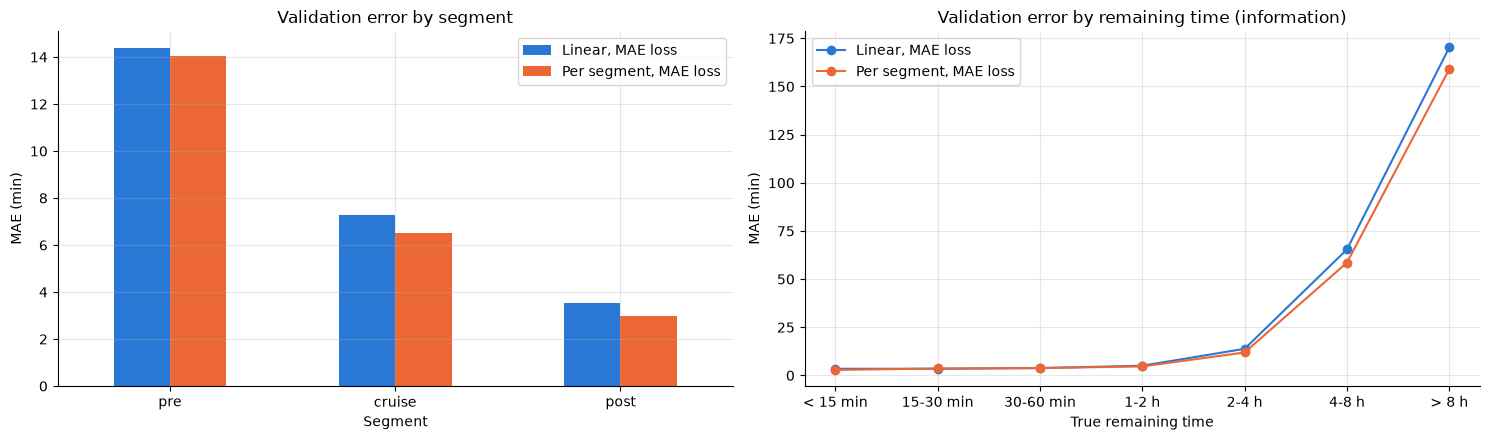

In [23]:
segment_pred = segment_predictions[best_strategy]
compared_models = {"Linear, MAE loss": mae_pred, "Per segment, MAE loss": segment_pred}

overall = pd.DataFrame({name: evaluate(y_val, pred, val_segment) for name, pred in compared_models.items()}).T
display(overall.round(2))
print("Paired bootstrap against the model of part 1 (a negative difference means a better MAE):")
display(bootstrap_comparison(y_val, compared_models, val_flight, reference="Linear, MAE loss"))

by_segment = overall[[f"MAE {segment} (min)" for segment in SEGMENTS]].T
by_segment.index = SEGMENTS
by_remaining_segment = pd.DataFrame(
    {name: np.abs(pred - y_val.to_numpy()) / 60 for name, pred in compared_models.items()},
    index=y_val.index,
).groupby(remaining_bins, observed=True).mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
by_segment.plot.bar(ax=axes[0], rot=0)
axes[0].set_xlabel("Segment")
axes[0].set_ylabel("MAE (min)")
axes[0].set_title("Validation error by segment")
by_remaining_segment.plot(ax=axes[1], marker="o")
axes[1].set_xlabel("True remaining time")
axes[1].set_ylabel("MAE (min)")
axes[1].set_title("Validation error by remaining time (information)")
plt.tight_layout()
plt.show()

- **One model per segment lowers the MAE from 8.1 to 7.5 minutes**, and the bootstrap confirms that the gain is real: −0.6 minute with a 95 % interval of about [−0.7, −0.4], far from 0. The guardrails improve too: the 95th percentile goes from 16.0 to 15.1 minutes and the MAE decreases in every segment. The median error goes from 3.0 to 2.6 minutes.
- **The gain is largest where the global model had to compromise the most:** −17 % in the descent and −10 % in the cruise, but only −2 % in the climb, which remains the hardest segment (~14 minutes). Before the cruise, the remaining time depends on the whole flight ahead, and the current state of the aircraft says little about it.
- **By remaining time** (information only), the segment models are better in the last 15 minutes and beyond 1 hour; between 15 and 60 minutes, the two are about equal (3.6 vs 3.4 minutes between 15 and 30 minutes).

### What the segment models learn

Two checks on the three segment models of the selected strategy: their training vs validation error, and their coefficients.

The coefficients need care: each segment model has its **own scaler**, so "+1 standard deviation" is not the same change from one segment to another. To compare the models, each weight is divided by the standard deviation of its scaler, which gives the effect of a fixed **physical** change, the other features being fixed. This makes the segment models comparable with each other and with the model of part 1.

In [24]:
segment_models = {segment: segment_results[(best_strategy, segment)]["model"] for segment in SEGMENTS}


def split_segment_model(model):
    """(preprocessor, regressor) of a segment model; the models of strategy A use the shared preprocessor."""
    if isinstance(model, Pipeline):
        return model.named_steps["preprocess"], model.named_steps["model"]
    return shared_preprocessor, model


gap_per_segment = {}
for segment, model in segment_models.items():
    preprocessor, regressor = split_segment_model(model)
    rows = in_train_segment[segment]
    train_prediction = regressor.predict(preprocessor.transform(X_train[rows])) * SECONDS_PER_HOUR
    gap_per_segment[segment] = {
        "train MAE (min)": mean_absolute_error(y_train[rows], train_prediction) / 60,
        "validation MAE (min)": segment_results[(best_strategy, segment)]["MAE (min)"],
    }
display(pd.DataFrame(gap_per_segment).T.round(2))

# Effect of a fixed physical change of one feature on the prediction (min), the other features fixed
PHYSICAL_STEPS = {
    "distance_to_arrival_km": (100, "+100 km"),
    "naive_time_to_arrival_s": (600, "+10 min"),
    "route_progress": (0.1, "+0.1"),
    "altitude_ft": (1_000, "+1,000 ft"),
    "speed_kt": (10, "+10 kt"),
    "vertical_rate_ft_min": (1_000, "+1,000 ft/min"),
    "heading_error_cos": (0.1, "+0.1"),
}


def physical_effects(preprocessor, regressor):
    """Weights converted from minutes per standard deviation to minutes per step of PHYSICAL_STEPS."""
    coefficients = pd.Series(regressor.coef_ * 60, index=preprocessor.get_feature_names_out())  # target in hours
    scale = pd.Series(preprocessor.named_transformers_["numeric"].scale_, index=NUMERIC_FEATURES)
    return pd.Series({f"{name} ({label})": coefficients[f"numeric__{name}"] / scale[name] * step
                      for name, (step, label) in PHYSICAL_STEPS.items()})


def mean_arrival_weight(preprocessor, regressor):
    """Mean absolute weight of the arrival-airport columns (min); one-hot columns are not scaled."""
    coefficients = pd.Series(regressor.coef_ * 60, index=preprocessor.get_feature_names_out())
    return coefficients[coefficients.index.str.startswith("airports__estArrivalAirport_")].abs().mean()


models_to_read = {"global (part 1)": (mae_model.named_steps["preprocess"], mae_model.named_steps["model"]),
                  **{segment: split_segment_model(model) for segment, model in segment_models.items()}}
display(pd.DataFrame({name: physical_effects(*parts) for name, parts in models_to_read.items()})
        .round(1).rename_axis("effect on the prediction (min)"))
print("Mean absolute weight of the arrival-airport columns (min): " + ", ".join(
    f"{name} {mean_arrival_weight(*parts):.1f}" for name, parts in models_to_read.items()))

,train MAE (min),validation MAE (min)
pre,14.50,14.04
cruise,6.62,6.53
post,2.94,2.96


,global (part 1),pre,cruise,post
effect on the prediction (min),,,,
distance_to_arrival_km (+100 km),6.2,6.9,2.5,2.9
naive_time_to_arrival_s (+10 min),1.4,0.3,6.8,4.7
route_progress (+0.1),-0.9,-0.4,-0.2,-0.1
"altitude_ft (+1,000 ft)",0.6,0.8,0.4,0.4
speed_kt (+10 kt),-0.1,-0.4,0.0,0.2
"vertical_rate_ft_min (+1,000 ft/min)",-0.3,-0.3,-0.4,0.4
heading_error_cos (+0.1),-0.2,-0.2,-3.4,-0.1


Mean absolute weight of the arrival-airport columns (min): global (part 1) 20.1, pre 34.8, cruise 20.6, post 4.7


- **No overfitting in any segment:** the training and validation errors are equal, up to the noise of the validation flights.
- **Each segment model predicts the remaining time in its own way**:
  - in the cruise and the descent, the naive time to arrival carries most of the weight (+6.8 and +4.7 minutes for +10 minutes of naive estimate): with a stable speed, distance / speed is a good estimate;
  - in the climb, the naive time is almost ignored (+0.3 minute) and the distance takes over (+6.9 minutes per 100 km): the aircraft is still accelerating, so distance / current speed overestimates the remaining time;
  - in the cruise, flying towards the destination (`heading_error_cos`) clearly shortens the predicted remaining time (−3.4 minutes for +0.1), a signal that the global model hardly uses (−0.2 minute);
  - the arrival airports weigh much more in the climb than in the descent (mean absolute weight of about 35 vs 5 minutes): far from the destination, the airport says a lot about the route still to fly; close to it, the distance and the speed already say most of what matters.
- The distance and the naive time are strongly correlated, so how a model splits its weight between them is partly arbitrary: the contrast between the segments is more reliable than each weight taken alone.

### The worst-predicted flights of the segment models

Same analysis as in section 6.5 for the per-segment model, next to the model of part 1: are its largest errors made on the same flights?

In [25]:
val_flights = flight_errors(validation, {"Linear, MAE loss": mae_pred, "Per segment, MAE loss": segment_pred})
flight_mae = {name: val_flights[f"{name}: MAE (min)"] for name in ["Linear, MAE loss", "Per segment, MAE loss"]}

print("Share of the total error made on the worst flights:")
display(pd.DataFrame({name: error_concentration(mae)[0] for name, mae in flight_mae.items()}).T.round(3))

worst_50 = {name: set(mae.nlargest(50).index) for name, mae in flight_mae.items()}
print(f"Flights shared by the 50 worst flights of the two models: "
      f"{len(worst_50['Linear, MAE loss'] & worst_50['Per segment, MAE loss'])} of 50")

print("Suspicious labels (same flags as in section 6.5):")
display(suspicious_label_report(flags, flight_mae).round(3))
display(pd.DataFrame({
    name: {"MAE, all the flights (min)": mae.mean(),
           "MAE without the suspicious labels (min)": mae[~flags["suspicious label"]].mean()}
    for name, mae in flight_mae.items()
}).T.round(2).rename_axis("information only"))

Share of the total error made on the worst flights:


,worst 1% of the flights,worst 5% of the flights,worst 10% of the flights
"Linear, MAE loss",0.264,0.521,0.597
"Per segment, MAE loss",0.280,0.527,0.602


Flights shared by the 50 worst flights of the two models: 48 of 50
Suspicious labels (same flags as in section 6.5):


,flights,share of the flights,"Linear, MAE loss: share of its worst 1 %","Linear, MAE loss: share of its total error","Per segment, MAE loss: share of its worst 1 %","Per segment, MAE loss: share of its total error"
same departure and arrival airport,76.0,0.015,0.385,0.160,0.385,0.159
implied speed < 0.6 x typical,84.0,0.016,0.423,0.199,0.423,0.197
implied speed > 1.6 x typical,46.0,0.009,0.115,0.043,0.115,0.056
suspicious label,206.0,0.040,0.923,0.402,0.923,0.412


,"MAE, all the flights (min)",MAE without the suspicious labels (min)
information only,,
"Linear, MAE loss",8.11,5.06
"Per segment, MAE loss",7.51,4.61


- **Same picture for the per-segment model:** its 5 % worst flights make 53 % of its error, and 48 of its 50 worst flights are also among the 50 worst flights of the model of part 1. The largest errors come from the flights, not from the model.
- **The suspicious labels make 41 % of its total error;** without them, its MAE would be 4.6 minutes instead of 7.5 (information only).
- **The gain of the segmentation does not come from these flights:** it is −0.6 minute on all the flights (8.1 → 7.5) and still −0.45 minute without the suspicious labels (5.1 → 4.6).

## 12. Summary

In [26]:
summary = pd.DataFrame({
    **{name: results[name] for name in ["Constant (train median)", "Naive: distance / speed", "Linear, MAE loss"]},
    "Per segment, MAE loss": evaluate(y_val, segment_pred, val_segment),
}).T
display(summary.round(2))

,MAE (min),median AE (min),P95 AE (min),MAE pre (min),MAE cruise (min),MAE post (min)
Constant (train median),44.01,23.52,149.03,78.59,34.22,29.01
Naive: distance / speed,16.06,8.71,42.53,30.68,13.59,6.37
"Linear, MAE loss",8.11,3.03,16.05,14.37,7.26,3.55
"Per segment, MAE loss",7.51,2.62,15.13,14.04,6.53,2.96


The two selected models and the naive estimate with their uncertainty, then their errors by remaining time.

In [27]:
main_models = {
    "Naive: distance / speed": validation["naive_time_to_arrival_s"].to_numpy(),
    "Linear, MAE loss": mae_pred,
    "Per segment, MAE loss": segment_pred,
}
print("MAE with 95 % confidence intervals (paired bootstrap over the validation flights)")
display(bootstrap_comparison(y_val, main_models, val_flight, reference="Linear, MAE loss"))

mae_table, relative_table = remaining_time_report(y_val, main_models)
print("MAE by remaining time (min), information only")
display(mae_table.round(1))
print("Relative error (%) = MAE / mean true remaining time of the group, information only")
display(relative_table.round(1))

MAE with 95 % confidence intervals (paired bootstrap over the validation flights)


,MAE (min),MAE 95 % CI,difference vs reference (min),difference 95 % CI
Naive: distance / speed,16.06,"[15.33, 16.91]",7.94,"[+7.64, +8.30]"
"Linear, MAE loss",8.11,"[7.45, 8.84]",0.0,"[+0.00, +0.00]"
"Per segment, MAE loss",7.51,"[6.86, 8.24]",-0.6,"[-0.73, -0.44]"


MAE by remaining time (min), information only


,share of rows (%),Naive: distance / speed,"Linear, MAE loss","Per segment, MAE loss"
< 15 min,14.9,4.3,3.5,2.8
15-30 min,19.3,8.4,3.4,3.6
30-60 min,31.3,10.9,3.8,3.8
1-2 h,22.0,14.8,5.0,4.7
2-4 h,9.1,31.3,13.8,11.9
4-8 h,2.5,91.2,65.4,58.6
> 8 h,1.0,193.3,170.3,159.0


Relative error (%) = MAE / mean true remaining time of the group, information only


,Naive: distance / speed,"Linear, MAE loss","Per segment, MAE loss"
< 15 min,58.3,46.6,38.3
15-30 min,36.8,14.9,15.7
30-60 min,25.4,8.8,8.9
1-2 h,17.6,6.0,5.5
2-4 h,19.8,8.8,7.5
4-8 h,27.3,19.6,17.5
> 8 h,31.5,27.8,25.9


The validation predictions of the two selected models are saved, so that the next notebooks can compare their models with them (same rows, paired bootstrap) without training them again.

In [28]:
reference_predictions = validation[FLIGHT_KEY + ["time"]].assign(**{
    "Linear, MAE loss": mae_pred,
    "Per segment, MAE loss": segment_pred,
})
LINEAR_PREDICTIONS_PATH.parent.mkdir(parents=True, exist_ok=True)
reference_predictions.to_parquet(LINEAR_PREDICTIONS_PATH, index=False)
print(f"Saved {LINEAR_PREDICTIONS_PATH.relative_to(PROJECT_DIR)}: {len(reference_predictions):,} rows")

Saved data/processed/predictions/validation_linear.parquet: 308,460 rows


The two selected models are also saved with `joblib`, to be evaluated once on the test flights at the end of the project, next to the other models, without training them again:
- **linear, MAE loss**: one pipeline (preprocessing + `SGDRegressor`);
- **per segment, MAE loss**: a dictionary `{segment: pipeline}`; each row has to be sent to the pipeline of its segment (`phase_of_flight`), as above.

Both are trained on the remaining time **in hours**: their predictions must be multiplied by 3,600 to get seconds.

In [29]:
# Every segment model as a full pipeline (the models of strategy A share an already fitted preprocessor)
segment_pipelines = {
    segment: model if isinstance(model, Pipeline) else Pipeline([("preprocess", shared_preprocessor), ("model", model)])
    for segment, model in segment_models.items()
}
LINEAR_MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(mae_model, LINEAR_MODEL_PATH)
joblib.dump(segment_pipelines, SEGMENT_MODELS_PATH)

# Check: the reloaded models give the same validation predictions
reloaded_linear = joblib.load(LINEAR_MODEL_PATH)
assert np.allclose(reloaded_linear.predict(X_val) * SECONDS_PER_HOUR, mae_pred)
reloaded_segments = joblib.load(SEGMENT_MODELS_PATH)
reloaded_segment_pred = np.full(len(y_val), np.nan)
for segment, pipeline in reloaded_segments.items():
    rows = (val_segment == segment).to_numpy()
    reloaded_segment_pred[rows] = pipeline.predict(X_val[rows]) * SECONDS_PER_HOUR
assert np.allclose(reloaded_segment_pred, segment_pred)
for path in (LINEAR_MODEL_PATH, SEGMENT_MODELS_PATH):
    print(f"Saved {path.relative_to(PROJECT_DIR)} ({path.stat().st_size / 1e3:.0f} kB)")

Saved data/models/linear_mae.joblib (84 kB)
Saved data/models/linear_mae_per_segment.joblib (250 kB)


**Takeaways — part 1 (one model for the whole flight).**
- Three linear candidates were tuned on the validation set (Ridge: α; Huber loss: α and δ; MAE loss: α) and compared: **the linear model with the MAE loss is selected**, with the lowest MAE and the best guardrails. The Ridge has a 95th percentile twice larger: the squared loss is driven by a few huge errors.
- The penalty strength α barely matters: there is far more data than weights. The penalty mostly keeps the solution unique and stable (redundant features, one-hot columns that sum to the intercept).
- The selected model halves the error of the naive physical estimate (MAE from ~16 to ~8 minutes). It relies on the distance to arrival, the naive time to arrival, the east-west position relative to the destination and the arrival airport; both the airport one-hot and the naive time bring a real gain.
- The error grows quickly with the remaining time: partly a genuinely harder problem (the relative error is lowest, 6 to 9 %, between 30 minutes and 4 hours), but beyond 4 hours the relative error doubles: few long-haul examples with a systematic underestimation, and impossible labels that weigh a lot far from the arrival.
- **The error is concentrated on a few flights with impossible labels** (section 6.5): 4 % of the validation flights (same departure and arrival airport, or an implied average speed far from normal) make 40 % of the error; without them, the MAE would be ~5 minutes. Detecting these labels in notebook 02 is the most promising improvement.
- The model does not overfit: it **underfits**. A single set of weights cannot describe the climb, the cruise and the approach at the same time.

**Takeaways — part 2 (one model per segment, phase of flight assumed known).**
- Three preprocessing strategies were compared and the best one was selected: **one preprocessor per segment, with the airport threshold expressed in flights**.
- The selected model (three sets of weights) lowers the MAE from ~8.1 to ~7.5 minutes compared with the model of part 1, a real gain according to the paired bootstrap, and improves the median and the 95th percentile. The gain is largest in the descent and the cruise; the climb remains the hard part.
- This is what **knowing the phase of flight** is worth for a linear model, under the assumption of this part: a phase accessible at any time (for live flights, from the flight plan for example).
- The per-segment model fails on the same flights as the single model (the suspicious labels make 41 % of its error), and its gain over the single model remains without them (−0.45 minute).

**Next steps.** A model that learns the interactions between the phase and the other features by itself, without being told the phase: gradient boosting (notebook 05, `HistGradientBoostingRegressor(loss="absolute_error")`), with early stopping on a validation set split by flight.